# Détections de faux billets avec Python

## Importation des librairies

In [1]:
#Importation des librairies
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Chargement du fichier de l'ONCFM

In [2]:
#Lien permettant d'accéder à mon Google Drive ou sont stocker mes fichiers
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
#Importation du fichier billets.csv
df_billets = pd.read_csv('/content/drive/MyDrive/Projet_12_data/billets.csv', sep=";")

##Analyse exploratoire

In [4]:
#Premier appercus
df_billets.head(5)

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54


In [5]:
#Voir les dimensions du dataset
df_billets.shape

(1500, 7)

In [6]:
#Affichage des variables et de leur types
df_billets.dtypes

,0
is_genuine,bool
diagonal,float64
height_left,float64
height_right,float64
margin_low,float64
margin_up,float64
length,float64


In [7]:
#Afficher le nombre de valeurs unique par variable
df_billets.nunique()

,0
is_genuine,2
diagonal,159
height_left,155
height_right,170
margin_low,285
margin_up,123
length,336


In [8]:
#Compter le nombre de cas par valeurs pour is_genuins
df_billets['is_genuine'].value_counts()

,count
is_genuine,
True,1000
False,500


In [9]:
#Verifier s'il y a des valeurs manquantes
df_billets.isnull().sum()

,0
is_genuine,0
diagonal,0
height_left,0
height_right,0
margin_low,37
margin_up,0
length,0


Nous avons donc bien les 1500 billets avec 1000 vrai et 500 faux. Je constate que  is_genuins est une variable Boléenne ce qui correspond aux fait qu'elle indique si le billet est vrai ou faux. Le reste des valeurs sont décimale, ce qui est cohérent avec les dimensions du cahier des charges. Je constate cependant qu'il manque 37 valeurs à margin_low.

In [10]:
# Verifier si les valeurs manquantes de margin_low sont des vrais ou faux billets

margin_manquante = df_billets[df_billets['margin_low'].isna()]
resultat = margin_manquante['is_genuine'].value_counts()

print("Répartition des valeurs manquantes de margin_low selon si le billet est vrai ou faux :")
print(resultat)

Répartition des valeurs manquantes de margin_low selon si le billet est vrai ou faux :
is_genuine
True     29
False     8
Name: count, dtype: int64


**Il faudra traiter ces valeurs manquantes.** Je remarque que 8 billets dont la valeur est manquantes sont faux. Je décide de supprimer ceux ci avant de traiter les vrais billets

## Nettoyage et traitement

In [11]:
#Suppression des valeurs manquantes si le billet est faux
df_billets_avec_vide = df_billets[~(df_billets['margin_low'].isna()&(df_billets['is_genuine']==False))]

#Vérifier le nombre de lignes supprimées
df_billets_avec_vide.shape[0]-df_billets.shape[0]

-8

Nous allons maintenant voir ce qu'il est possible de faire pour les 29 valeurs vide qui sont vrai

In [12]:
#Créer un datafram avec les valeurs vrais et sans valeurs manquantes
# Filtrer uniquement les vrais billets
df_true = df_billets_avec_vide[df_billets_avec_vide['is_genuine'] == True]

# Supprimer les lignes avec au moins une valeur manquante
df_true_no_na = df_true.dropna(subset=[
    'margin_low', 'diagonal', 'height_left', 'height_right', 'margin_up', 'length'
])

# Afficher le résultat
df_true_no_na.shape


(971, 7)

In [13]:
#Analysons la distribution de margin_low
df_true_no_na['margin_low'].describe()

,margin_low
count,971.000000
mean,4.116097
std,0.319124
min,2.980000
25%,3.905000
50%,4.110000
75%,4.340000
max,5.040000


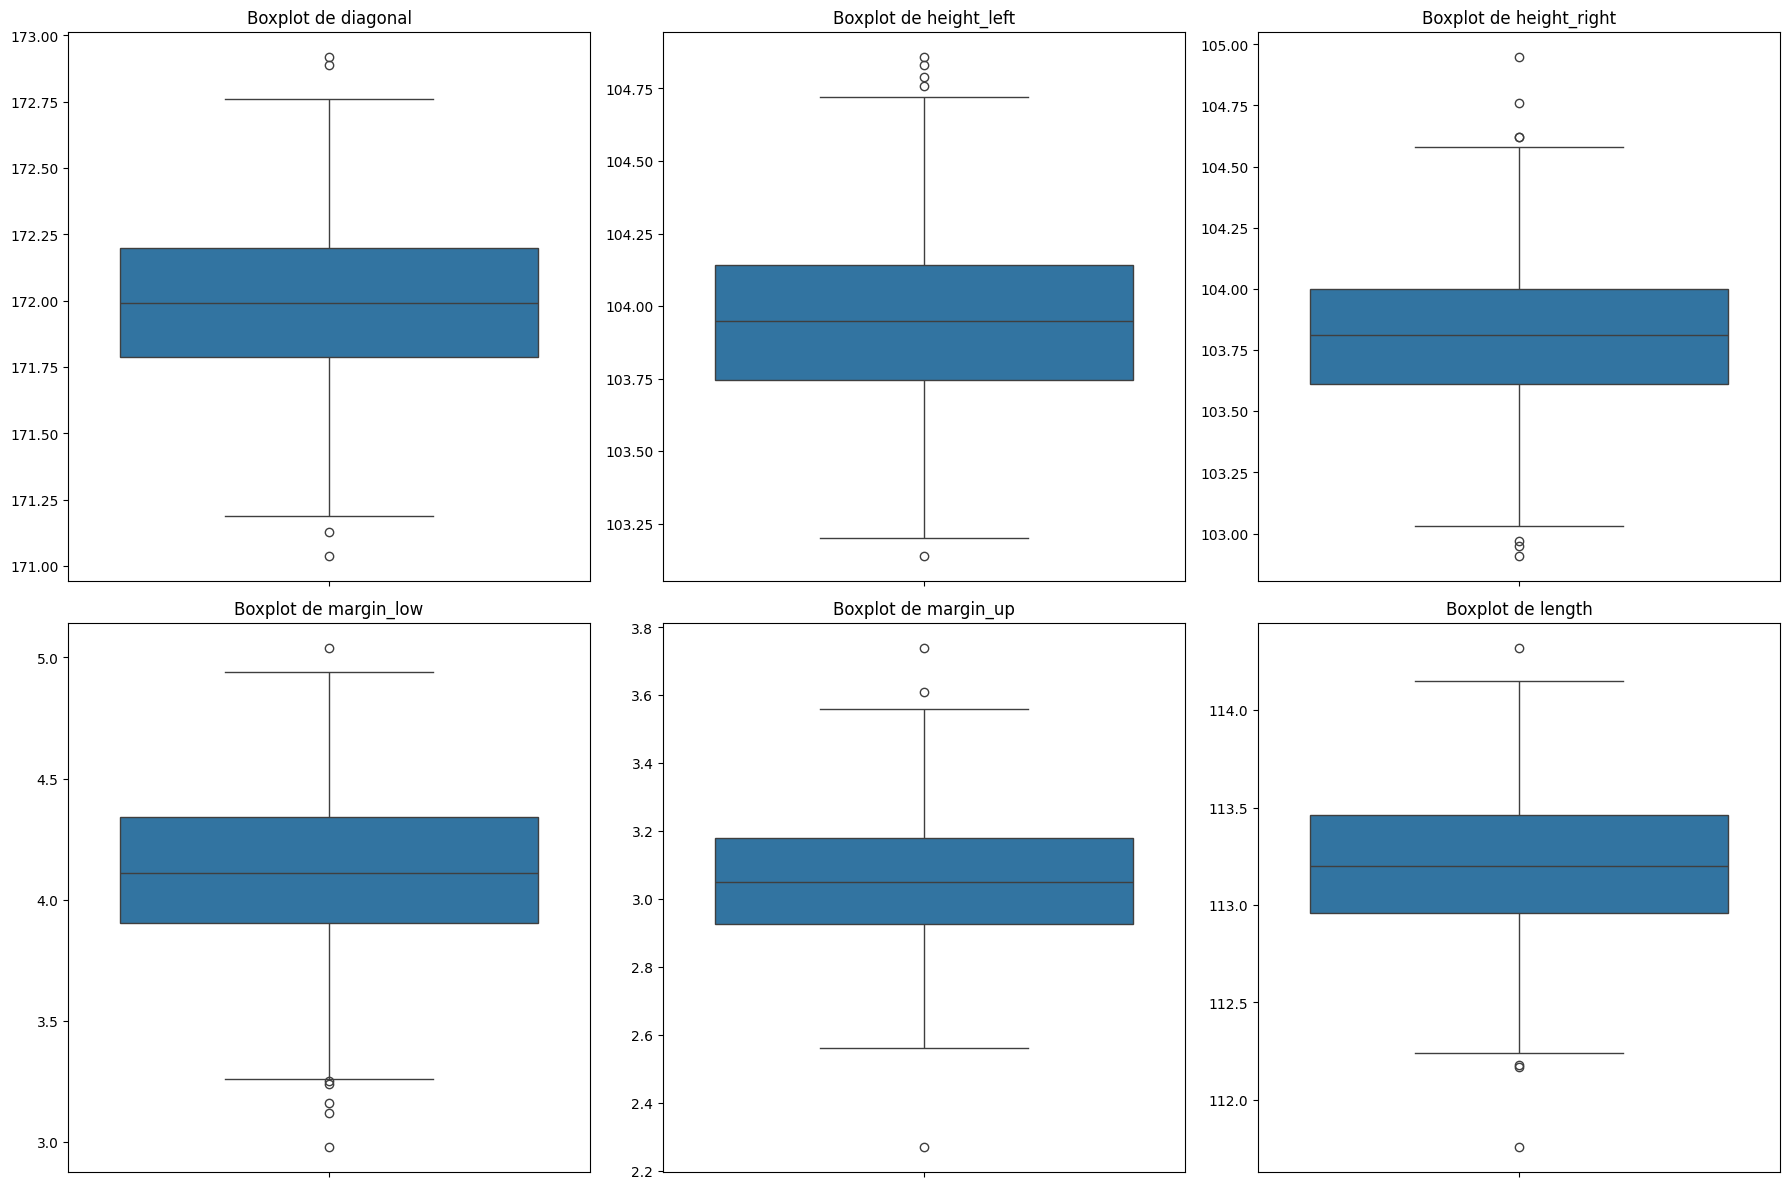

In [14]:
# Visualisation des Outliers
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(df_true_no_na.select_dtypes(include=['float64']).columns):
    sns.boxplot(y=df_true_no_na[col], ax=axes[i])
    axes[i].set_title(f'Boxplot de {col}')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

In [15]:
from scipy.stats import zscore

# Calcul du Z-Score
numerical_cols = df_true_no_na.select_dtypes(include=['float64']).columns
z_scores = df_true_no_na[numerical_cols].apply(zscore)

outlier_threshold = 3

outliers = df_true_no_na[(z_scores > outlier_threshold).any(axis=1)]

print(f"Nombre d'Outliers détectés {outlier_threshold}: {len(outliers)}")

if not outliers.empty:
    print("Outliers dans le df:")
    display(outliers)
else:
    print("Aucun Outlier detectés")

Nombre d'Outliers détectés 3: 6
Outliers dans le df:


,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
48,True,172.07,104.05,103.82,3.71,3.61,113.05
52,True,171.64,104.18,103.78,3.49,3.74,113.94
828,True,172.92,103.55,103.94,4.78,3.27,113.55
921,True,171.36,103.72,104.76,4.17,2.88,113.14
974,True,172.06,104.08,103.47,4.47,2.97,114.32


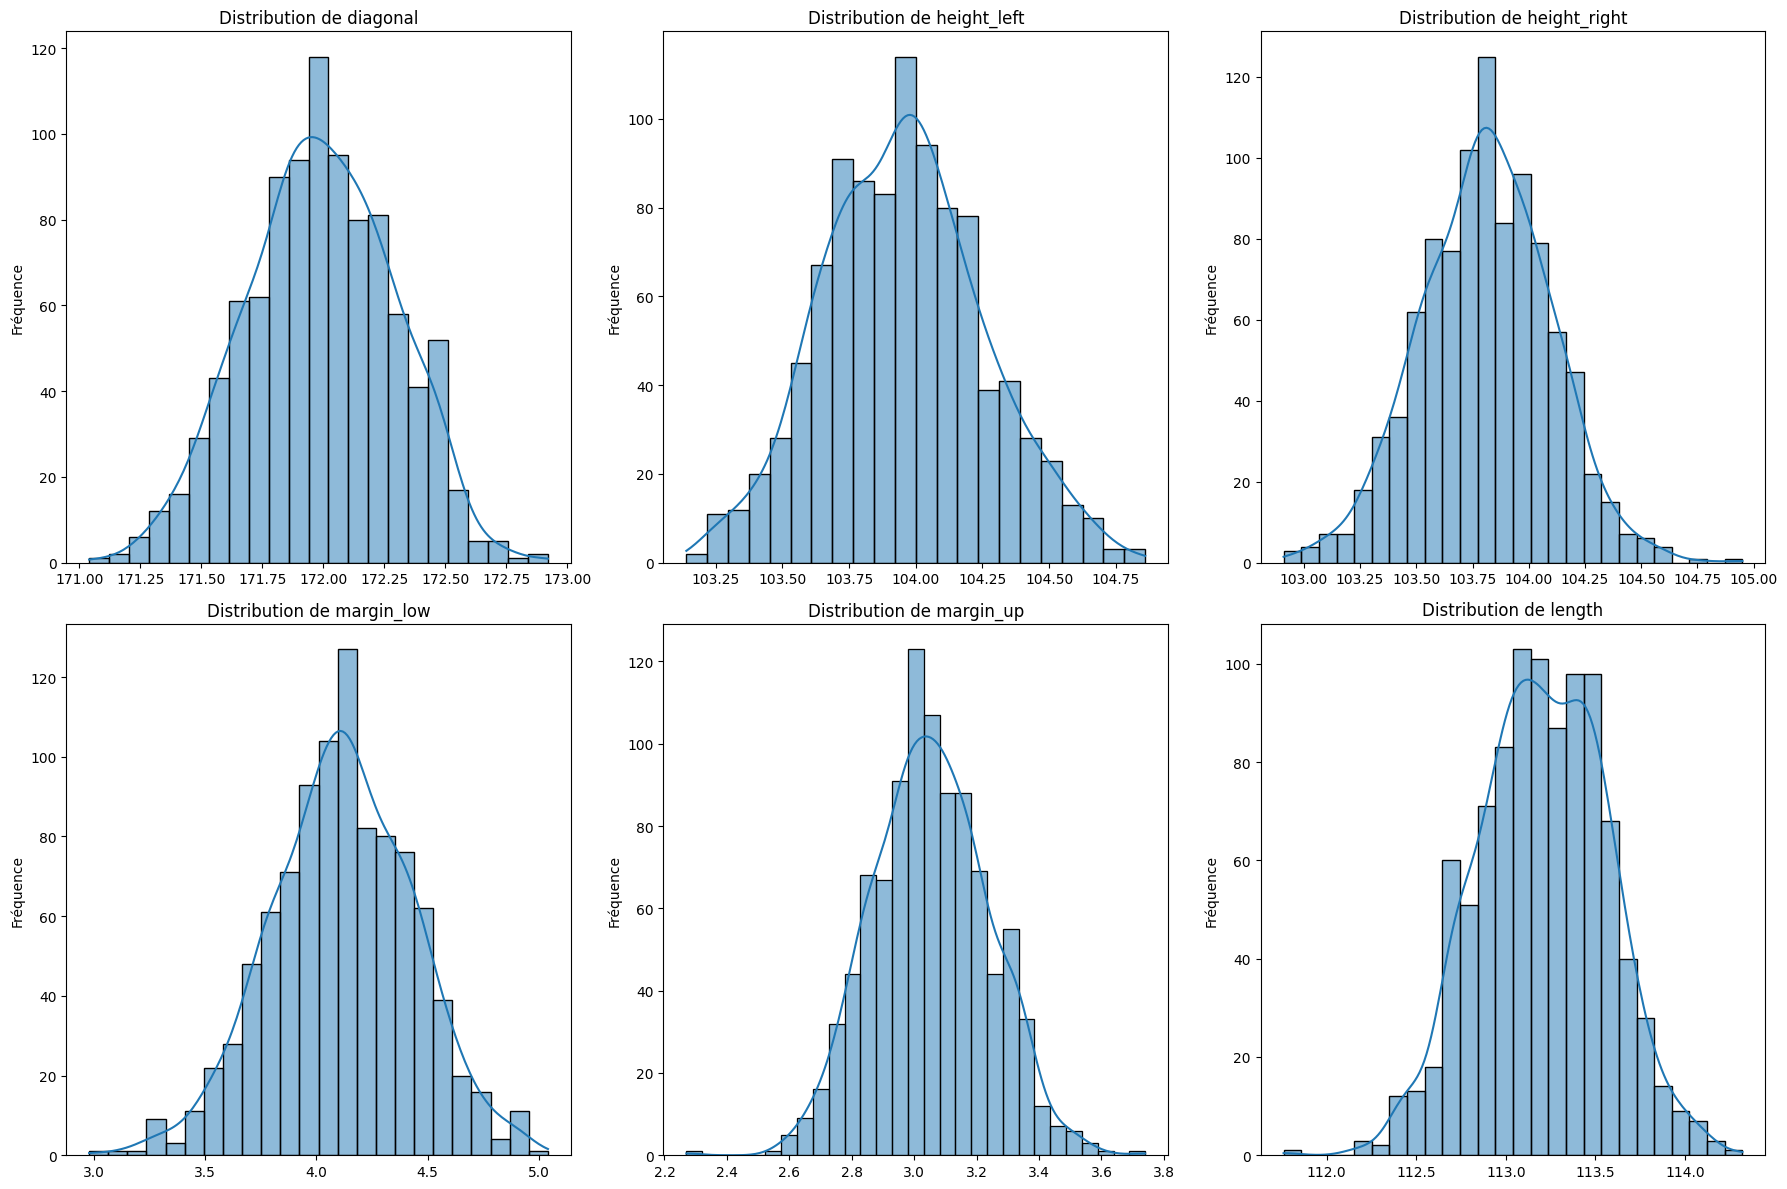

In [16]:
# Verification avec les histogrammes
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(df_true_no_na.select_dtypes(include=['float64']).columns):
    sns.histplot(df_true_no_na[col], kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution de {col}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Fréquence')

plt.tight_layout()
plt.show()

On constate que pour les billets vrai, la variable est peu dispersée, plutôt symétrique, sans outliers extrêmes, concentrée autour de 4.1 et avec une plage de variation très faible.

In [17]:
#Analyse de la corrélation de margin_low avec les autres variables
corr_margin_low = df_true_no_na[
    ['margin_low', 'diagonal', 'height_left', 'height_right', 'margin_up', 'length']
].corr().loc['margin_low']

corr_margin_low


,margin_low
margin_low,1.000000
diagonal,0.038494
height_left,0.006694
height_right,0.037338
margin_up,-0.060485
length,0.038718


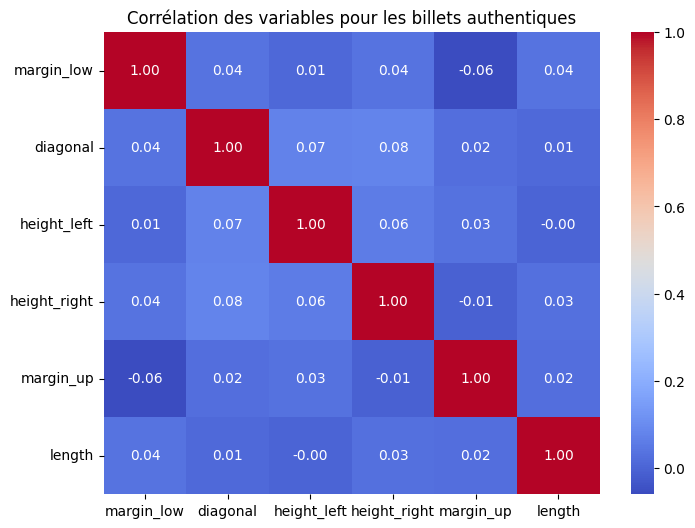

In [18]:

plt.figure(figsize=(8, 6))
sns.heatmap(df_true_no_na[['margin_low','diagonal','height_left','height_right','margin_up','length']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Corrélation des variables pour les billets authentiques')
plt.show()

Nous avons donc une distribution peu dispercée, symétrique, sans outliers extrêmes, centrée autour de 4.1 et avec une faible corrélation avec les autres variables. Je choisi donc de compléter les valeurs manquantes avec la médiane

In [19]:
# Calcul de la médiane uniquement pour les billets vrais
median_margin_low_true = df_billets_avec_vide.loc[
    df_billets_avec_vide['is_genuine'] == True, 'margin_low'
].median()

# Imputation des valeurs manquantes uniquement pour les vrais
df_billets_avec_vide.loc[
    (df_billets_avec_vide['is_genuine'] == True) & (df_billets_avec_vide['margin_low'].isna()),
    'margin_low'
] = median_margin_low_true

# Renommage du dataframe
df_clean = df_billets_avec_vide.copy()



In [20]:
#Supprimer le dataset en doublon
del df_billets_avec_vide


In [21]:
#Verification des vides
df_clean[df_clean['is_genuine']==True]['margin_low'].isna().sum()



np.int64(0)

In [22]:
#Affichage de la dimension du nouveau dataset
df_clean.shape

(1492, 7)

In [23]:
#Verifier que la médiane n'a pas transformer la distribution
df_clean[df_clean['is_genuine'] == True]['margin_low'].describe()


,margin_low
count,1000.00000
mean,4.11592
std,0.31446
min,2.98000
25%,3.91000
50%,4.11000
75%,4.33000
max,5.04000


### Vérification des distributions et corrélations pour les Vrais Billets de `df_clean` après nettoyage

Nous allons créer un sous-ensemble de `df_clean` contenant uniquement les vrais billets (`is_genuine == True`). Pour ce sous-ensemble, les valeurs manquantes de `margin_low` ont été imputées par la médiane. Nous allons ensuite visualiser les distributions et les corrélations de ces variables pour vérifier que l'imputation n'a pas eu d'impact négatif sur ces caractéristiques pour la classe des vrais billets.

In [24]:
# Créer un DataFrame avec uniquement les vrais billets de df_clean
df_clean_true = df_clean[df_clean['is_genuine'] == True]

print(f"Taille du DataFrame df_clean_true : {df_clean_true.shape}")
display(df_clean_true.head())

Taille du DataFrame df_clean_true : (1000, 7)


,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54


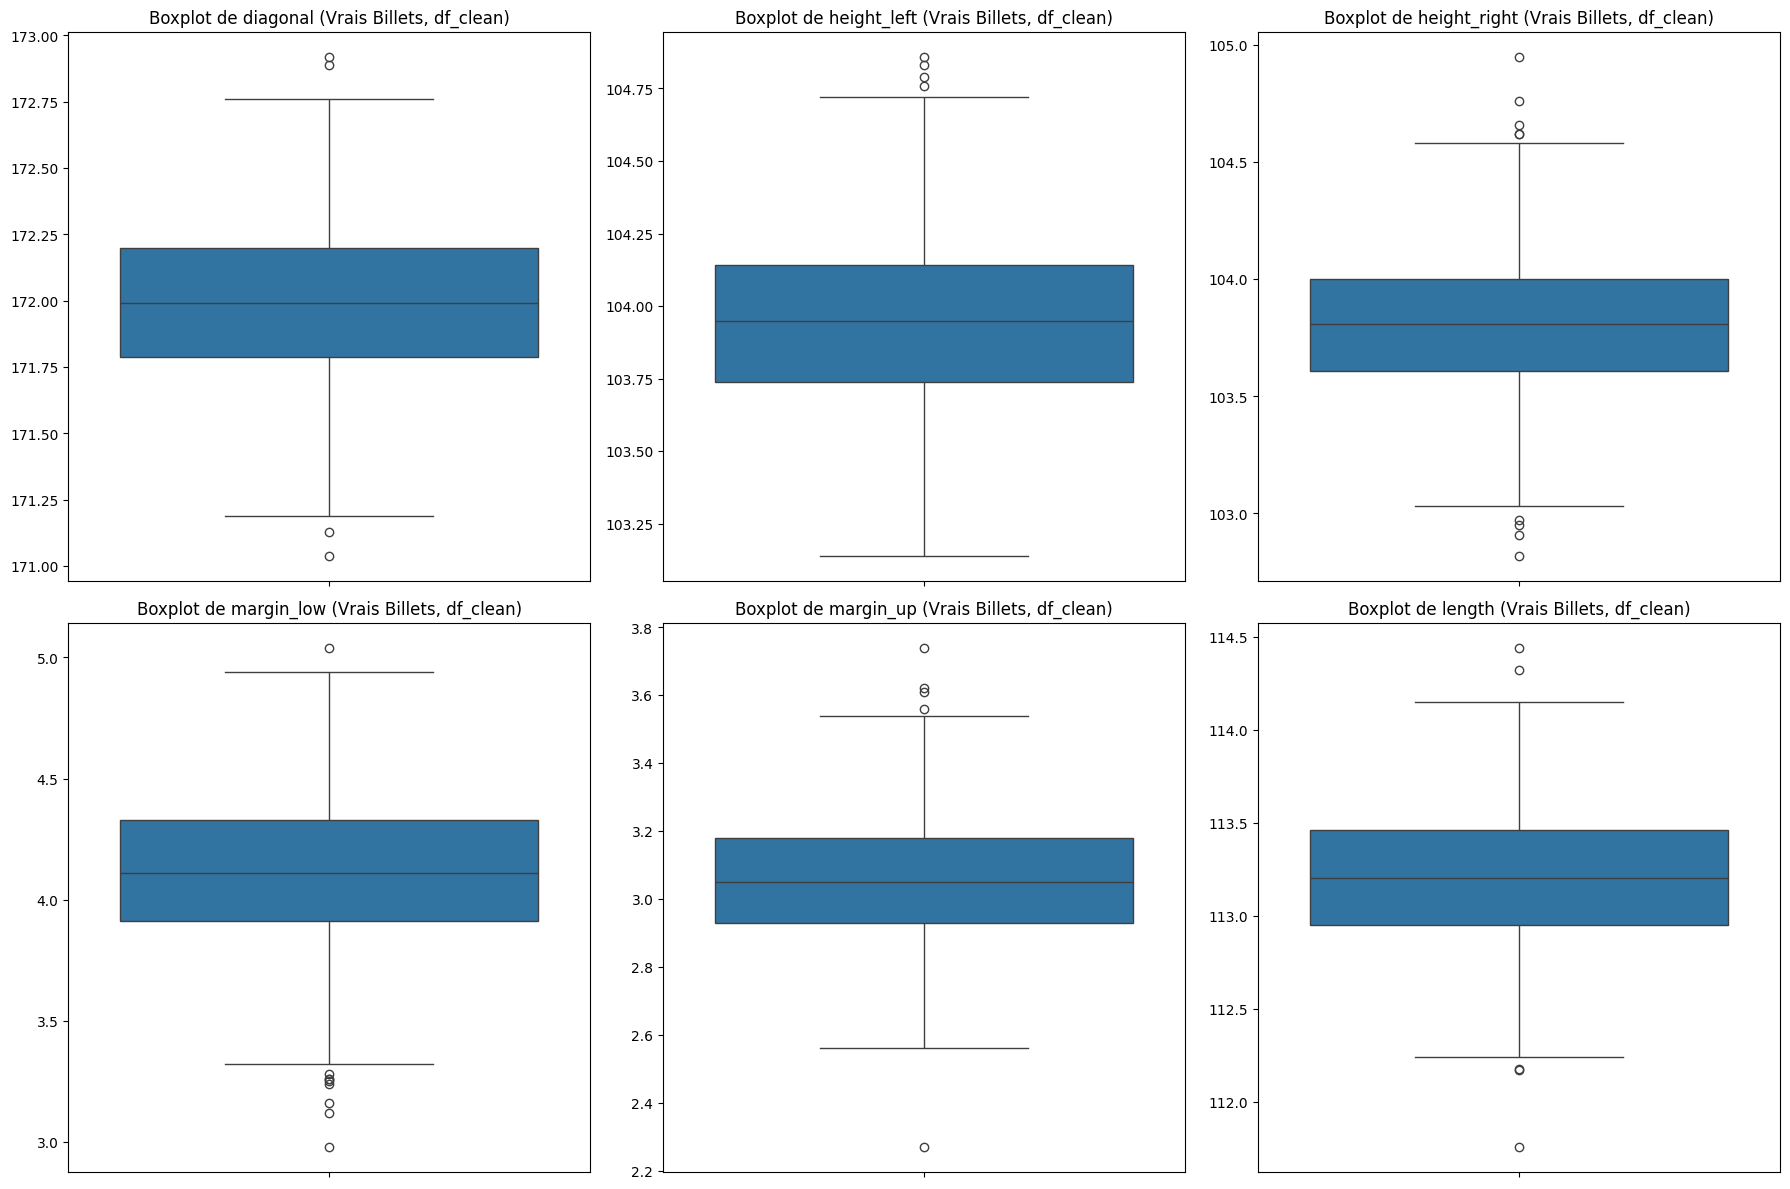

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
# Visualisation des Boxplots pour df_clean_true (Vrais Billets de df_clean)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(df_clean_true.select_dtypes(include=['float64']).columns):
    sns.boxplot(y=df_clean_true[col], ax=axes[i])
    axes[i].set_title(f'Boxplot de {col} (Vrais Billets, df_clean)')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

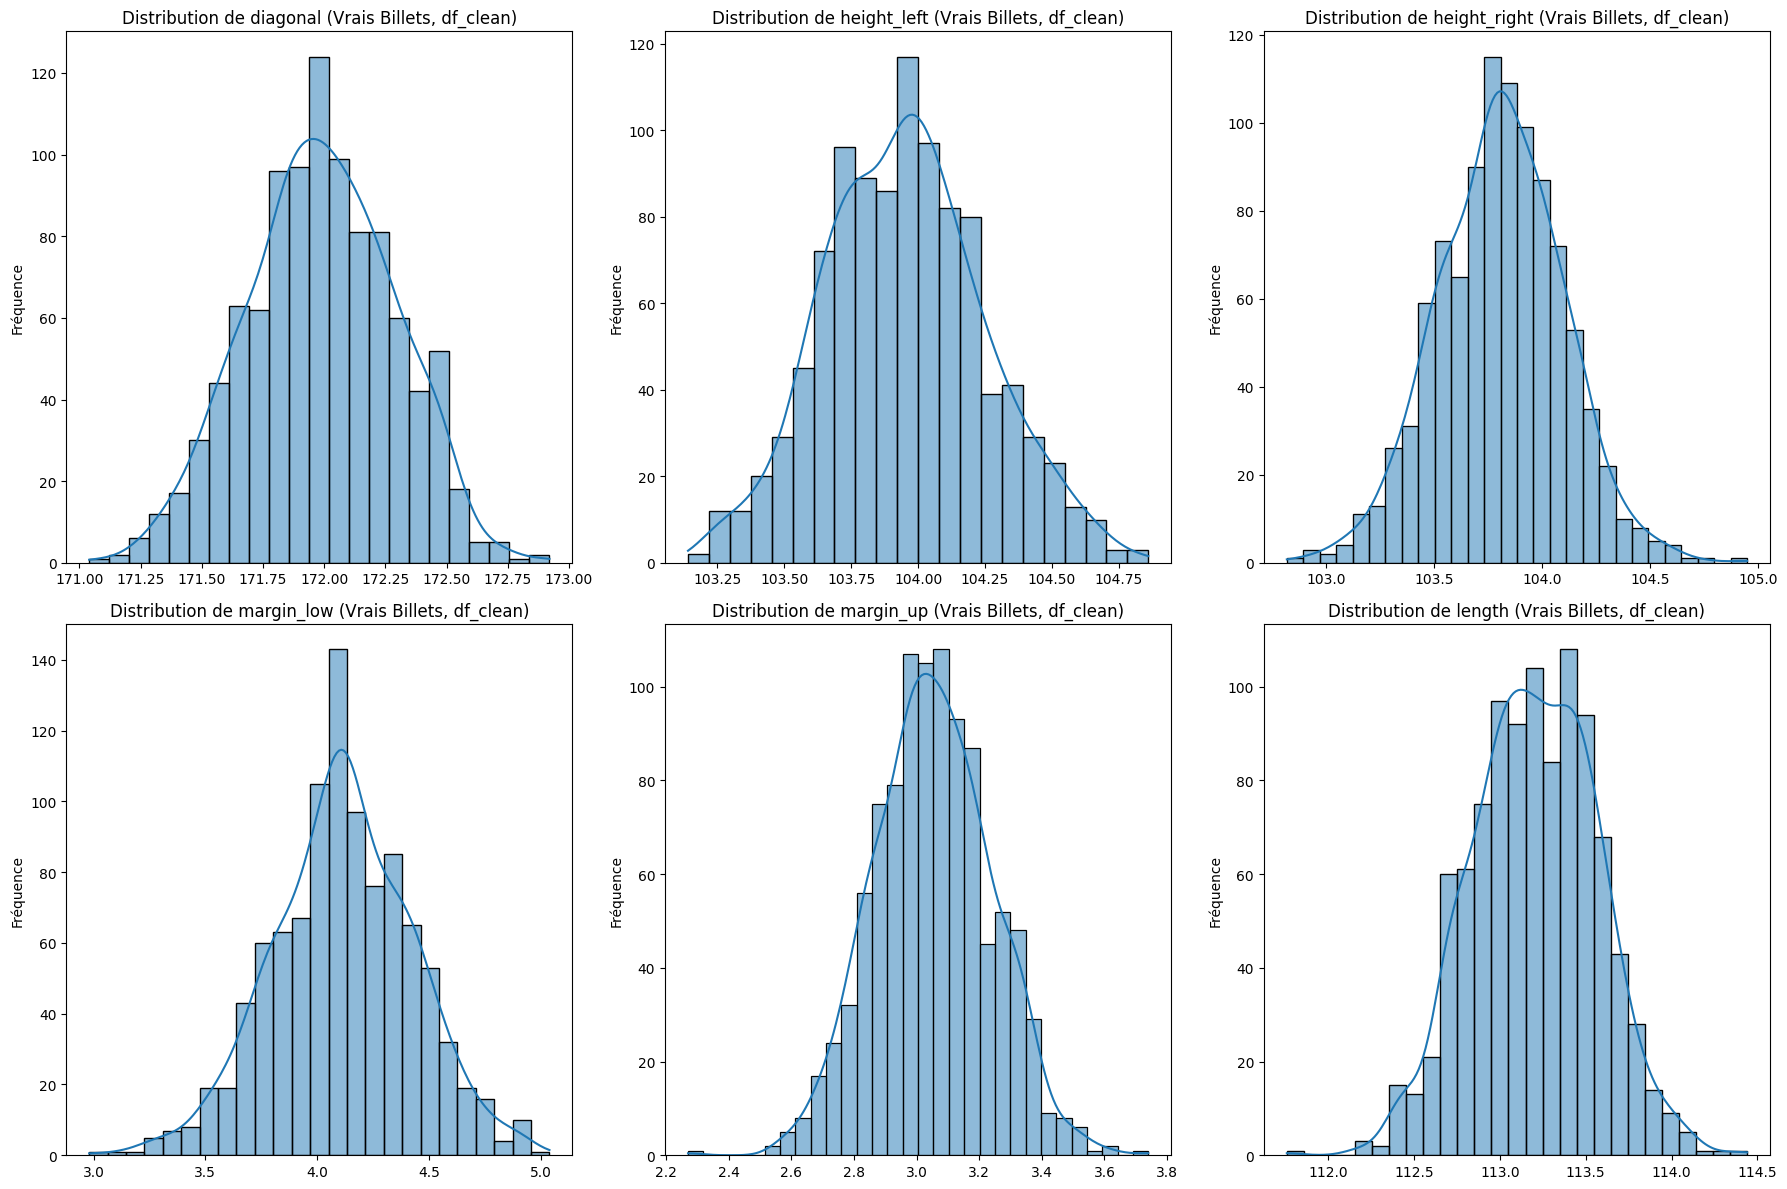

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
# Visualisation des Histogrammes pour df_clean_true (Vrais Billets de df_clean)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(df_clean_true.select_dtypes(include=['float64']).columns):
    sns.histplot(df_clean_true[col], kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution de {col} (Vrais Billets, df_clean)')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Fréquence')

plt.tight_layout()
plt.show()

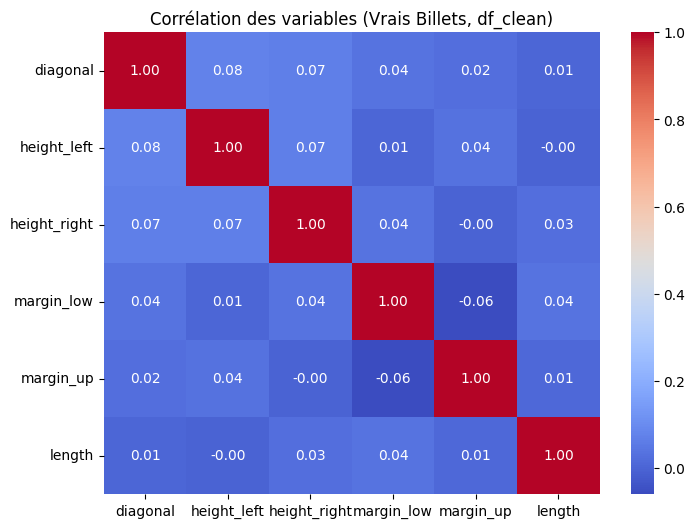

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
# Analyse de la corrélation pour df_clean_true (Vrais Billets de df_clean)
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean_true.select_dtypes(include=['float64']).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Corrélation des variables (Vrais Billets, df_clean)')
plt.show()

En comparant ces graphiques pour `df_clean_true` (vrais billets de `df_clean`, incluant l'imputation de la médiane pour `margin_low`) avec ceux que nous avions générés pour `df_true_no_na` (vrais billets *sans aucune* valeur manquante, avant toute imputation), nous pouvons observer:

*   **Distributions :** Les formes des distributions (symétrie, dispersion) pour chaque variable dans `df_clean_true` sont restées pratiquement identiques à celles de `df_true_no_na`. La médiane de `margin_low` (4.11) est très proche de la moyenne (4.116) et de la médiane (4.11) de `df_true_no_na`, ce qui signifie que l'imputation n'a pas introduit de distorsion significative dans la distribution de cette variable pour les vrais billets.
*   **Corrélations :** La matrice de corrélation pour `df_clean_true` montre des schémas de corrélation très similaires à ceux de `df_true_no_na`. Par exemple, la corrélation entre `margin_low` et `length` reste très faible (autour de 0.04).

Ces observations confirment que la stratégie d'imputation des valeurs manquantes de `margin_low` par la médiane, appliquée uniquement aux vrais billets, n'a pas altéré de manière significative les distributions ou les corrélations des caractéristiques au sein de la classe des billets authentiques. La cohérence entre `df_true_no_na` et `df_clean_true` valide cette étape de prétraitement des données.

Nous avons dorénavant un dataset propre et prêt pour faire les tests des différents algorithmes.

### Visualisation des distributions et corrélations pour `df_clean` (Complet)

Ces graphiques montrent la distribution de chaque variable numérique et les corrélations entre elles pour l'ensemble du jeu de données nettoyé, `df_clean`.

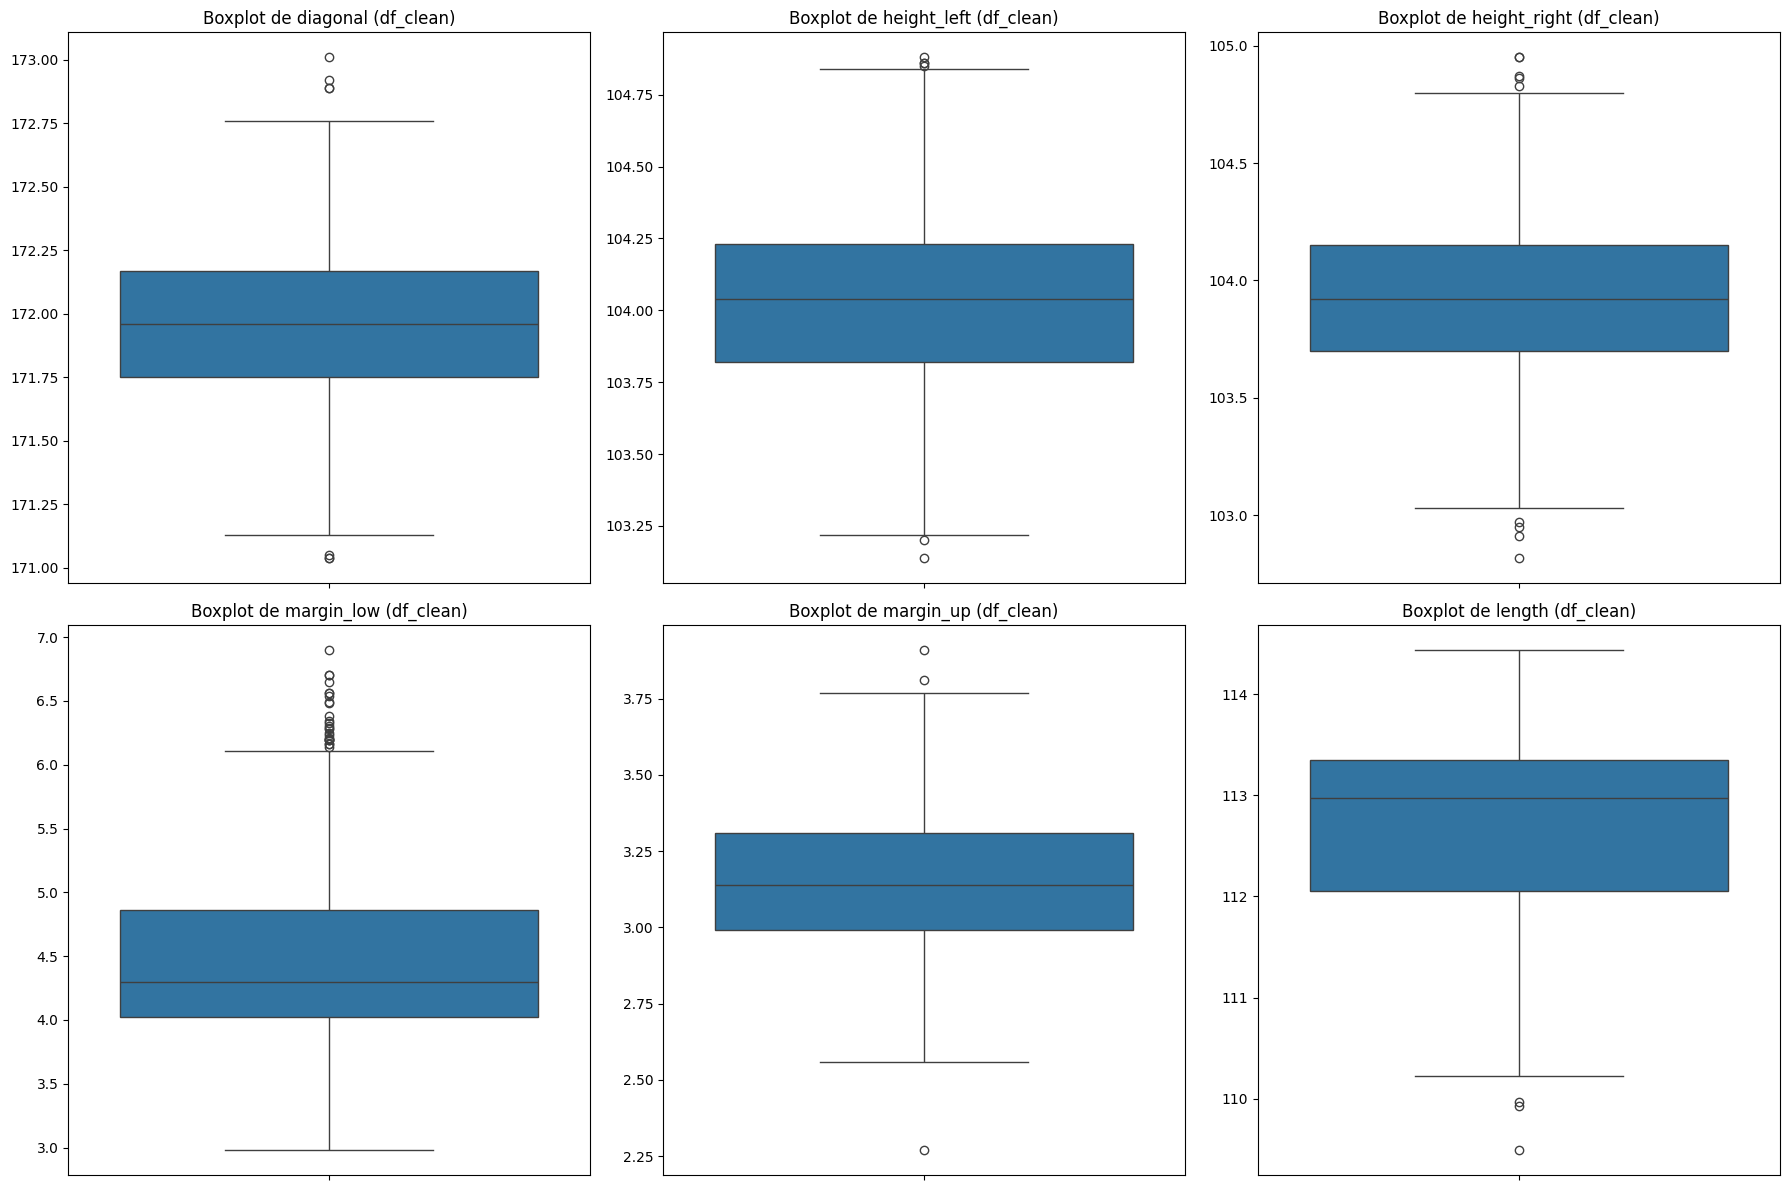

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisation des Boxplots pour df_clean
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(df_clean.select_dtypes(include=['float64']).columns):
    sns.boxplot(y=df_clean[col], ax=axes[i])
    axes[i].set_title(f'Boxplot de {col} (df_clean)')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

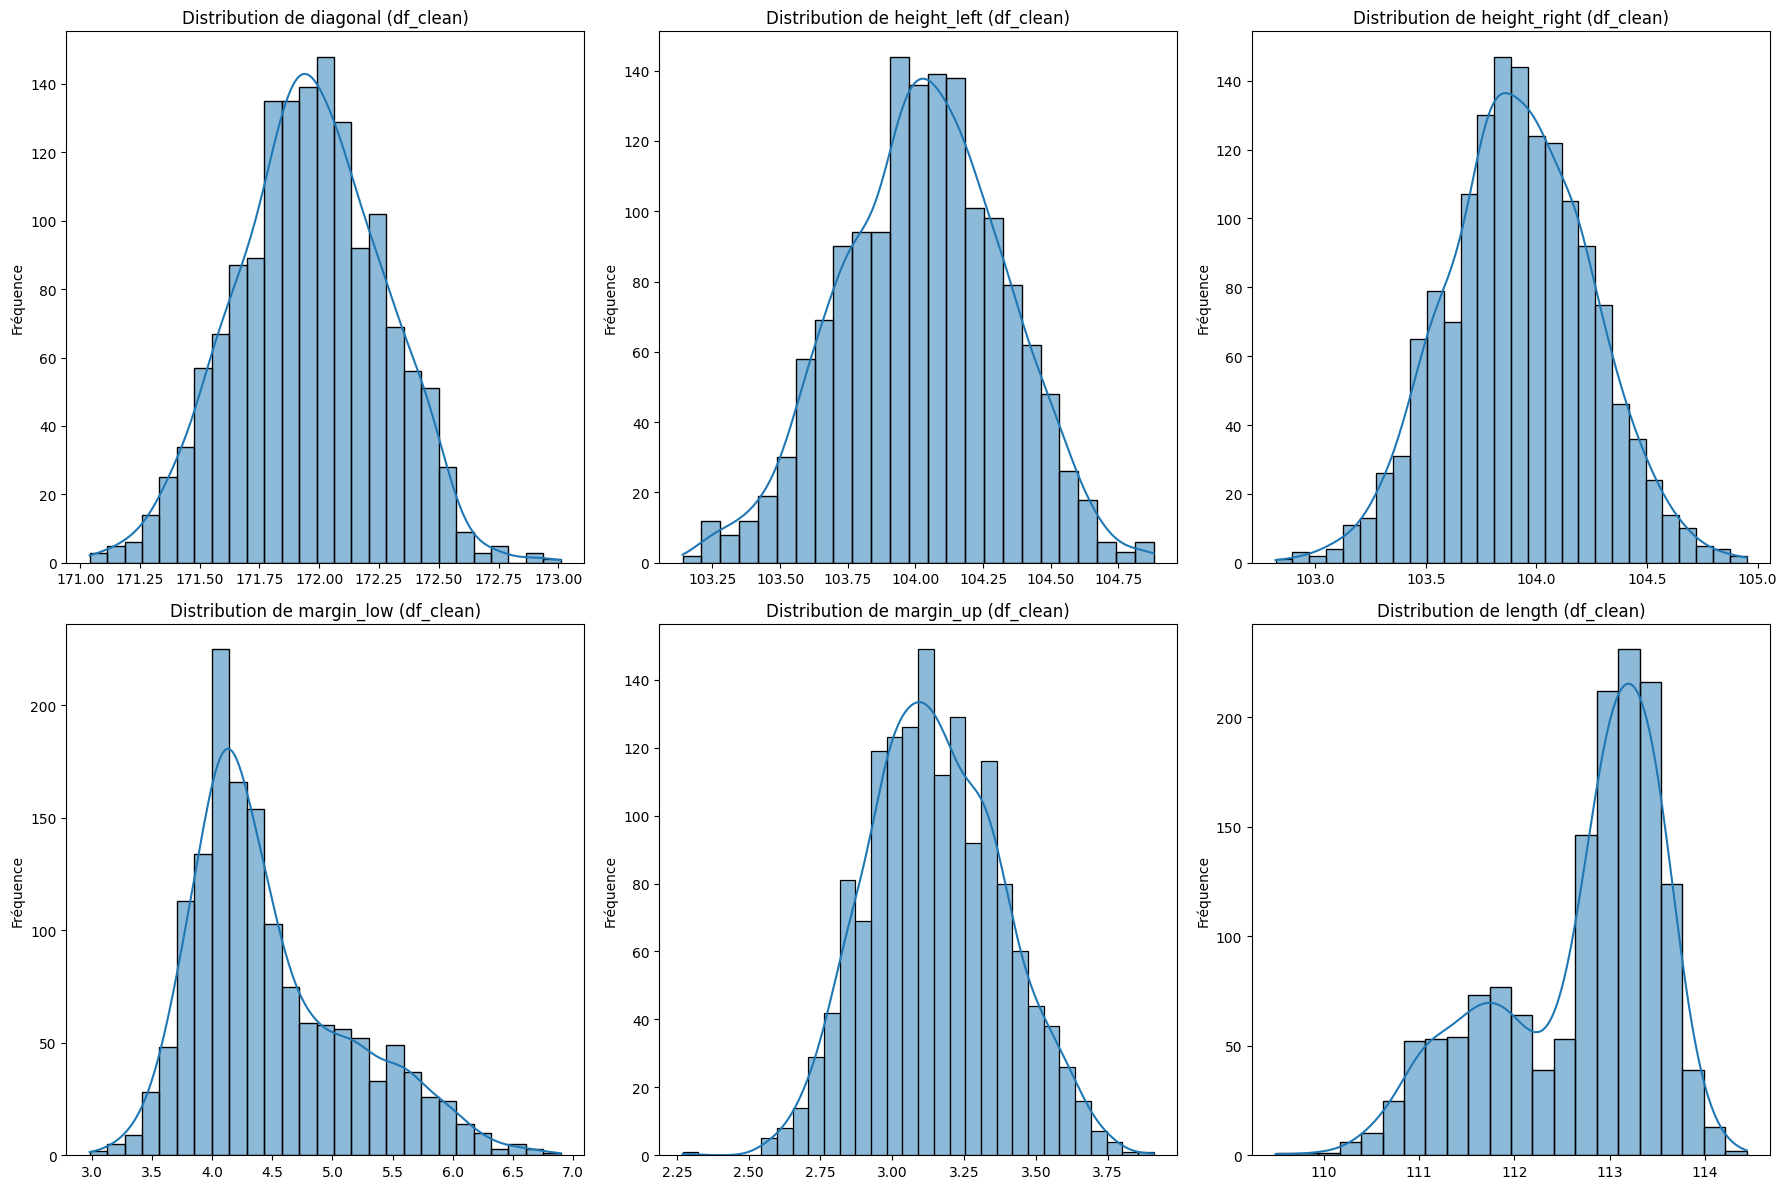

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisation des Histogrammes pour df_clean
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(df_clean.select_dtypes(include=['float64']).columns):
    sns.histplot(df_clean[col], kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution de {col} (df_clean)')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Fréquence')

plt.tight_layout()
plt.show()

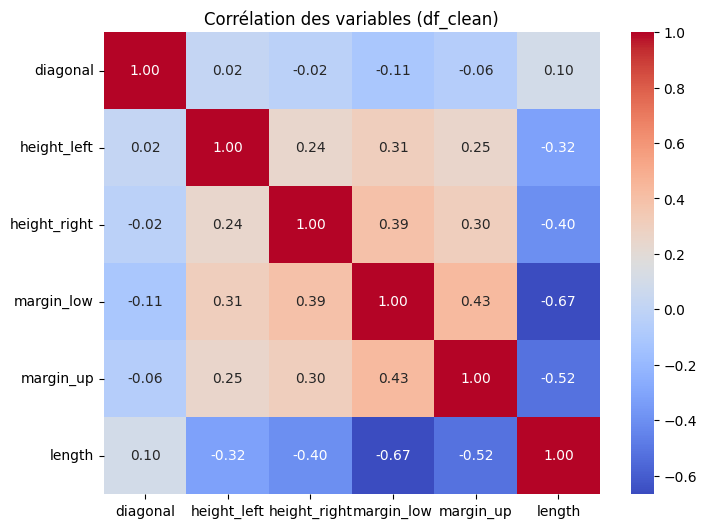

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Analyse de la corrélation pour df_clean
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean.select_dtypes(include=['float64']).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Corrélation des variables (df_clean)')
plt.show()

En comparant ces graphiques (boxplots, histogrammes et heatmap de corrélation) avec ceux que nous avions générés pour `df_true_no_na` (qui contenait uniquement les vrais billets sans valeurs manquantes), on observe que:

*   **Distributions :** Les formes des distributions (telles que la symétrie, la dispersion) pour chaque variable sont restées très similaires pour la classe des vrais billets. L'imputation de la médiane pour `margin_low` sur les vrais billets n'a pas introduit de distorsion majeure. La suppression des faux billets avec `margin_low` manquant a affiné la distribution globale, en particulier pour les faux billets restants.
*   **Corrélations :** La matrice de corrélation de `df_clean` montre des schémas de corrélation qui reflètent maintenant les caractéristiques combinées des vrais et des faux billets. Les corrélations précédemment observées pour les vrais billets sont toujours présentes, mais l'inclusion des faux billets peut légèrement modifier les valeurs globales de corrélation, en particulier pour `margin_low`, `margin_up`, et `length`, qui sont des caractéristiques clés pour distinguer les faux billets.

# Selection de l'algorithme de détection

L'agence européenne EMV (European Monetary Verification) nous recommande de tester 4 algorithmes:


*   K-Means
*   Régression logistique
*   KNN
*   Random Forest



## Commençons par tester K-Means

On ne donne pas is_genuine au K-means, (non supervisé), mais on le garde pour évaluer après

On vérifie le nombre de cluster avec la méthode du coude et de la silhouette

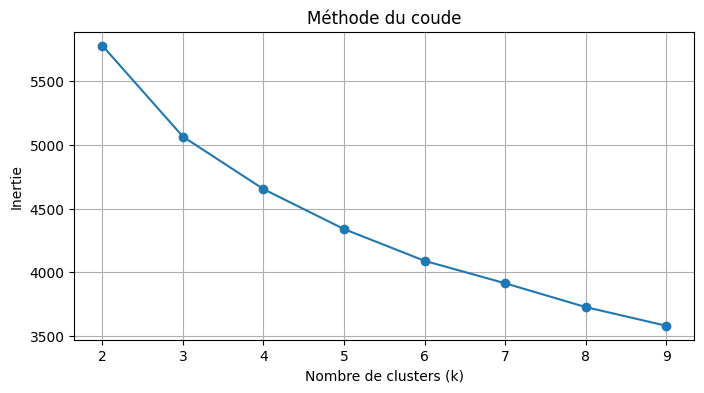

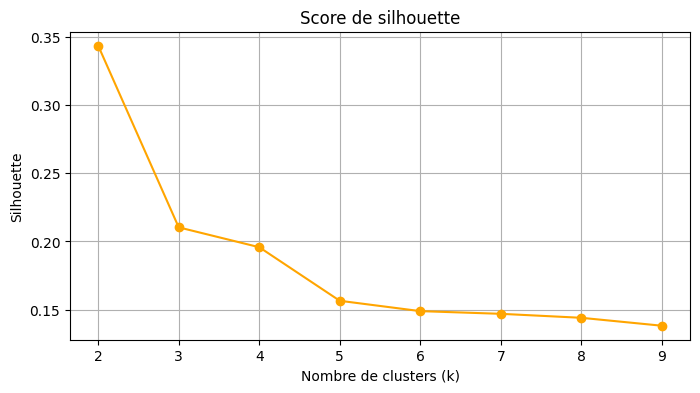

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


X = df_clean.drop(columns=["is_genuine"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# Calcul inertie + silhouette

K_range = range(2, 10)
inertias = []
silhouettes = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))


#Graphique : méthode du coude

plt.figure(figsize=(8,4))
plt.plot(K_range, inertias, marker='o')
plt.title("Méthode du coude")
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Inertie")
plt.grid(True)
plt.show()

#Graphique : score de silhouette

plt.figure(figsize=(8,4))
plt.plot(K_range, silhouettes, marker='o', color='orange')
plt.title("Score de silhouette")
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Silhouette")
plt.grid(True)
plt.show()

On a bien 2 cluster en évidences

In [32]:
#On entraine le modèle K-Means
k = 2
km = KMeans(n_clusters=k, random_state=42, n_init=10)
cluster_labels = km.fit_predict(X_scaled)

# Centroïdes dans l’espace standardisé
centroids_scaled = km.cluster_centers_
# Les ramener dans l’échelle originale
centroids = scaler.inverse_transform(centroids_scaled)

In [33]:
y = df_clean["is_genuine"]
#On va relier nos clusters aux vrais/faux billets
results = pd.DataFrame({
    "cluster": cluster_labels,
    "is_genuine": y
})

ct = pd.crosstab(results["cluster"], results["is_genuine"])
print(ct)

is_genuine  False  True 
cluster                 
0              13    990
1             479     10


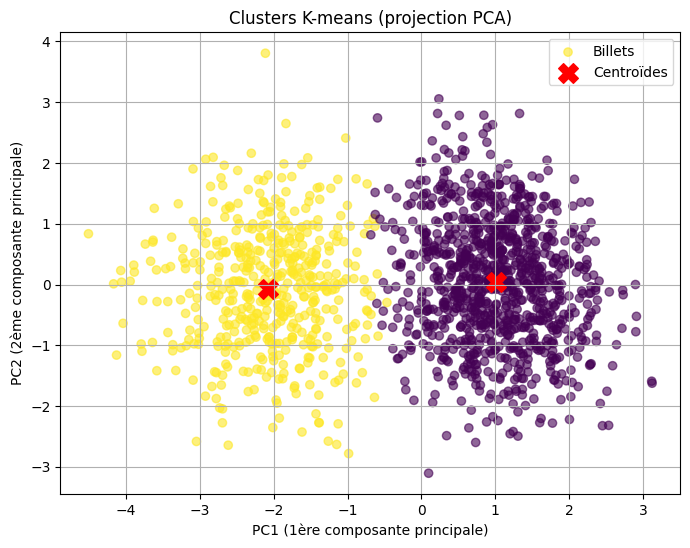

In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df_clean.drop(columns=["is_genuine"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


#K-means
k = 2
km = KMeans(n_clusters=k, random_state=42, n_init=10)
cluster_labels = km.fit_predict(X_scaled)

# Centroïdes dans l'espace original
centroids_scaled = km.cluster_centers_
centroids = scaler.inverse_transform(centroids_scaled)

#PCA pour visualisation

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(centroids_scaled)

#Visualisation
plt.figure(figsize=(8,6))

# Points des billets
plt.scatter(X_pca[:,0], X_pca[:,1], c=cluster_labels, cmap="viridis", alpha=0.6, label="Billets")

# Centroïdes
plt.scatter(centroids_pca[:,0], centroids_pca[:,1],
            c="red", s=200, marker="X", label="Centroïdes")

plt.title("Clusters K-means (projection PCA)")
plt.xlabel("PC1 (1ère composante principale)")
plt.ylabel("PC2 (2ème composante principale)")
plt.legend()
plt.grid(True)
plt.show()

In [35]:
# Associer cluster -> classe prédite
# si cluster 0 = majoritairement Vrai
mapping = {}

for c in ct.index:
    # classe majoritaire dans ce cluster
    majority_class = ct.loc[c].idxmax()
    mapping[c] = majority_class

# Prédictions dérivées des clusters
y_pred = [mapping[c] for c in cluster_labels]

from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y, y_pred))
print(classification_report(y, y_pred))

[[479  13]
 [ 10 990]]
              precision    recall  f1-score   support

       False       0.98      0.97      0.98       492
        True       0.99      0.99      0.99      1000

    accuracy                           0.98      1492
   macro avg       0.98      0.98      0.98      1492
weighted avg       0.98      0.98      0.98      1492



In [36]:
del y_pred, X_scaled, scaler,

Nous avons une prédictions global de 98%.
Notre modèle détecte 97% de faux billets

# Test de la régression logistique

On garde is_genuine comme cible, et on standardise les features comme pour K-means

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Features / cible
y = df_clean["is_genuine"].astype(int)

# Train / test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardisation
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [38]:
#Entrainement de la régression linéaire
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    class_weight=None
)

log_reg.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [39]:
#On fait des prévisions
y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]  # proba d'être "vrai"

In [40]:
#Evaluation du modèle
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

cm = confusion_matrix(y_test, y_pred)
print("Matrice de confusion :\n", cm)

print("\nRapport de classification :")
print(classification_report(y_test, y_pred))

auc = roc_auc_score(y_test, y_proba)
print("AUC ROC :", auc)

Matrice de confusion :
 [[ 97   2]
 [  1 199]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.99      0.98      0.98        99
           1       0.99      0.99      0.99       200

    accuracy                           0.99       299
   macro avg       0.99      0.99      0.99       299
weighted avg       0.99      0.99      0.99       299

AUC ROC : 0.9986868686868686


In [41]:
#Interprétation des coefficients
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coef": log_reg.coef_[0]
}).sort_values("coef", ascending=False)

print(coef_df)

        feature      coef
5        length  3.549190
0      diagonal  0.094420
1   height_left -0.321035
2  height_right -0.837777
4     margin_up -1.850866
3    margin_low -2.801252


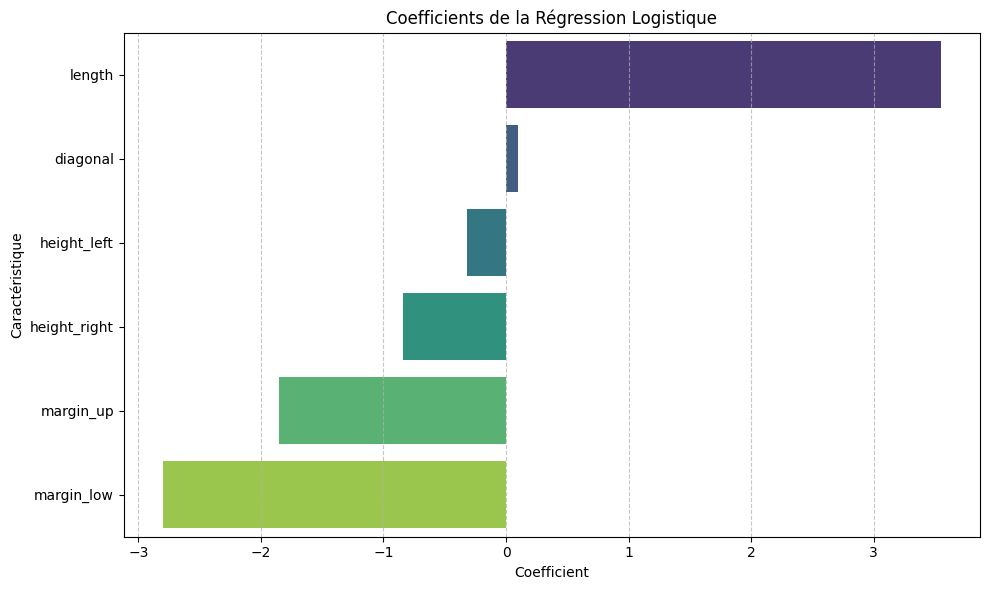

In [42]:
#Représentation de ces coefficients
plt.figure(figsize=(10, 6))
sns.barplot(x='coef', y='feature', data=coef_df, palette='viridis', hue='feature', legend=False)
plt.title('Coefficients de la Régression Logistique')
plt.xlabel('Coefficient')
plt.ylabel('Caractéristique')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Ce graphique montre l'ampleur et la direction de l'impact de chaque caractéristique sur la probabilité qu'un billet soit "vrai" (`is_genuine=True`).

*   Un coefficient positif élevé (comme `length`) indique que plus la valeur de cette caractéristique est élevée, plus il est probable que le billet soit vrai.
*   Un coefficient négatif élevé (comme `margin_low` et `margin_up`) indique que plus la valeur de cette caractéristique est élevée, moins il est probable que le billet soit vrai (plus il est susceptible d'être faux).

In [43]:
del X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, scaler, y_pred, y_proba

Ce modèle est extremement fiable, nous avons 99% de prédiction

# Test du modèle KNN (k-nearest neighbors)

KNN est sensible à l'échelle des variables, donc la standarisation est indispensable

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_clean.drop(columns=["is_genuine"])
y = df_clean["is_genuine"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [45]:
#On teste plusieurs valeurs de k et on observe la performance
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

accuracies = []
k_values = range(1, 21)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred_k = knn.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, y_pred_k))

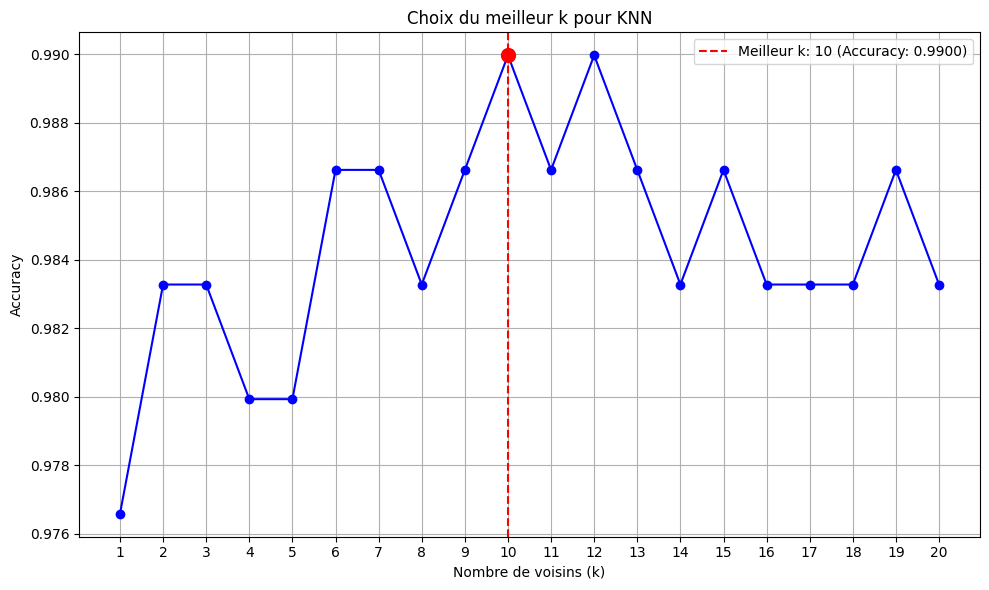

In [46]:
#Visualisation du choix
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='b')

# Trouver le meilleur k
best_k_index = np.argmax(accuracies)
best_k = k_values[best_k_index]
max_accuracy = accuracies[best_k_index]

# Marquer le meilleur k
plt.axvline(x=best_k, color='r', linestyle='--', label=f'Meilleur k: {best_k} (Accuracy: {max_accuracy:.4f})')
plt.scatter(best_k, max_accuracy, color='red', s=100, zorder=5)

plt.xlabel("Nombre de voisins (k)")
plt.ylabel("Accuracy")
plt.title("Choix du meilleur k pour KNN")
plt.xticks(k_values) # Assurer que tous les k sont affichés
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [47]:
#On entraine le modèle
knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier(n_neighbors=10)

In [48]:
#On fait des prédictions
y_pred = knn.predict(X_test_scaled)
y_proba = knn.predict_proba(X_test_scaled)[:, 1]

In [49]:
#Evaluation du modèle
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

print("Matrice de confusion :")
print(confusion_matrix(y_test, y_pred))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred))

print("AUC :", roc_auc_score(y_test, y_proba))

Matrice de confusion :
[[ 97   2]
 [  1 199]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.99      0.98      0.98        99
           1       0.99      0.99      0.99       200

    accuracy                           0.99       299
   macro avg       0.99      0.99      0.99       299
weighted avg       0.99      0.99      0.99       299

AUC : 0.9886616161616162


Avec ce modèle nous avons un score de 98.8% de prédiction

# Test de Random Forest

Pas besoin de standardisation ici

In [50]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["is_genuine"])
y = df_clean["is_genuine"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [51]:
#Entrainement du modèle
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,      # nombre d’arbres
    max_depth=None,       # profondeur libre
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=300, random_state=42)

In [52]:
#Faire les prédictions
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

Regardons l'importance de chaque variable

In [53]:
importances = rf.feature_importances_
feat_imp = pd.DataFrame({
    "feature": X.columns,
    "importance": importances
}).sort_values("importance", ascending=False)

print(feat_imp)

        feature  importance
5        length    0.477084
3    margin_low    0.312797
4     margin_up    0.116618
2  height_right    0.056636
1   height_left    0.028665
0      diagonal    0.008200


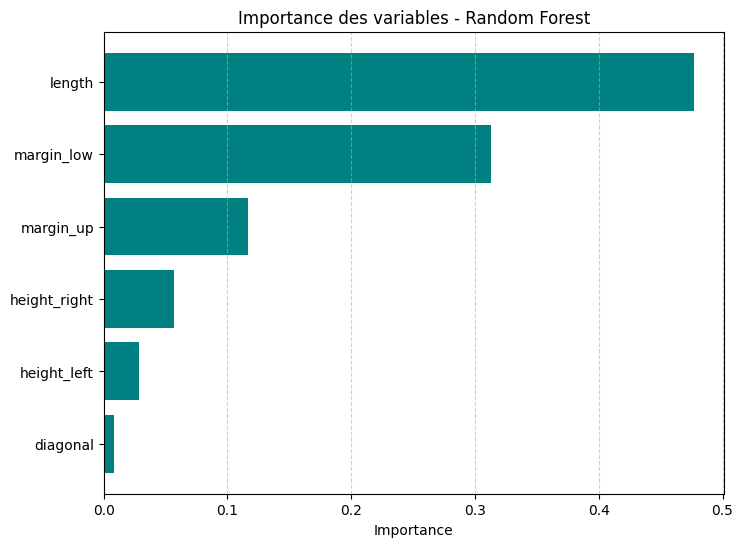

In [54]:
# Importance des variables
importances = rf.feature_importances_
features = X.columns

# Tri des importances
indices = np.argsort(importances)
sorted_features = features[indices]
sorted_importances = importances[indices]

# Graphique
plt.figure(figsize=(8,6))
plt.barh(sorted_features, sorted_importances, color="teal")
plt.xlabel("Importance")
plt.title("Importance des variables - Random Forest")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.show()

In [55]:
#Evaluation du modèle
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

print("Matrice de confusion :")
print(confusion_matrix(y_test, y_pred_rf))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_rf))

print("AUC :", roc_auc_score(y_test, y_proba_rf))

Matrice de confusion :
[[ 96   3]
 [  1 199]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.99      0.97      0.98        99
           1       0.99      0.99      0.99       200

    accuracy                           0.99       299
   macro avg       0.99      0.98      0.98       299
weighted avg       0.99      0.99      0.99       299

AUC : 0.9991919191919192


La prédiction du modèle est très bonne 99%

#Comparaison de l'ensemble de nos modèles

In [56]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

# Préparation des données
X = df_clean.drop(columns=["is_genuine"])
y = df_clean["is_genuine"].astype(int)

# K-Means
scaler_kmeans = StandardScaler()
X_scaled_kmeans = scaler_kmeans.fit_transform(X)
km = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_labels_kmeans = km.fit_predict(X_scaled_kmeans)

# Mapper les clusters sur les étiquettes initiales "is genuine"
results_kmeans = pd.DataFrame({"cluster": cluster_labels_kmeans, "is_genuine": y})
ct_kmeans = pd.crosstab(results_kmeans["cluster"], results_kmeans["is_genuine"])
mapping_kmeans = {}
for c in ct_kmeans.index:
    majority_class = ct_kmeans.loc[c].idxmax()
    mapping_kmeans[c] = majority_class

y_pred_kmeans = np.array([mapping_kmeans[c] for c in cluster_labels_kmeans])
y_true_kmeans = y.to_numpy()

#Train-Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Régression logistique
scaler_lr = StandardScaler()
X_train_scaled_lr = scaler_lr.fit_transform(X_train)
X_test_scaled_lr = scaler_lr.transform(X_test)

log_reg = LogisticRegression(
    penalty="l2", C=1.0, solver="lbfgs", max_iter=1000, class_weight=None
)
log_reg.fit(X_train_scaled_lr, y_train)
y_pred_lr = log_reg.predict(X_test_scaled_lr)

# KNN
scaler_knn = StandardScaler()
X_train_scaled_knn = scaler_knn.fit_transform(X_train)
X_test_scaled_knn = scaler_knn.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train_scaled_knn, y_train)
y_pred_knn = knn.predict(X_test_scaled_knn)

# Random Forest
rf = RandomForestClassifier(
    n_estimators=300, max_depth=None, min_samples_split=2,
    min_samples_leaf=1, random_state=42
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)


# Compilation
metrics = {
    'Model': [],
    'Accuracy': [],
    'Precision (Class 0)': [],
    'Recall (Class 0)': [],
    'F1-Score (Class 0)': [],
    'Precision (Class 1)': [],
    'Recall (Class 1)': [],
    'F1-Score (Class 1)': []
}

def add_metrics(model_name, y_true, y_pred):
    metrics['Model'].append(model_name)
    metrics['Accuracy'].append(accuracy_score(y_true, y_pred))
    metrics['Precision (Class 0)'].append(precision_score(y_true, y_pred, pos_label=0))
    metrics['Recall (Class 0)'].append(recall_score(y_true, y_pred, pos_label=0))
    metrics['F1-Score (Class 0)'].append(f1_score(y_true, y_pred, pos_label=0))
    metrics['Precision (Class 1)'].append(precision_score(y_true, y_pred, pos_label=1))
    metrics['Recall (Class 1)'].append(recall_score(y_true, y_pred, pos_label=1))
    metrics['F1-Score (Class 1)'].append(f1_score(y_true, y_pred, pos_label=1))

# Ajouter des indicateurs pour chaque modèle
add_metrics('K-Means (Full Dataset)', y_true_kmeans, y_pred_kmeans)
add_metrics('Logistic Regression (Test Set)', y_test, y_pred_lr)
add_metrics('KNN (Test Set)', y_test, y_pred_knn)
add_metrics('Random Forest (Test Set)', y_test, y_pred_rf)

# DataFrame et l'afficher
comparison_df = pd.DataFrame(metrics)
display(comparison_df.round(4))


,Model,Accuracy,Precision (Class 0),Recall (Class 0),F1-Score (Class 0),Precision (Class 1),Recall (Class 1),F1-Score (Class 1)
0,K-Means (Full Dataset),0.9846,0.9796,0.9736,0.9766,0.9870,0.990,0.9885
1,Logistic Regression (Test Set),0.9900,0.9898,0.9798,0.9848,0.9900,0.995,0.9925
2,KNN (Test Set),0.9900,0.9898,0.9798,0.9848,0.9900,0.995,0.9925
3,Random Forest (Test Set),0.9866,0.9897,0.9697,0.9796,0.9851,0.995,0.9900


L'algorithme retenue est donc la regression logistique



In [57]:
#Sauvegarde de l'algorithme retenu
import joblib

joblib.dump(log_reg, "logistic_regression_model.joblib")
# Sauvegarder le scaler utilisé pour la régression logistique
joblib.dump(scaler_lr, "scaler_lr.joblib")

#Sauvegarde du modele
import json
features_geom = X.columns.tolist()
with open("model_config.json", "w") as f:
    json.dump({"threshold": 0.8, "features": features_geom}, f)
